# Conformal Pillbox Geometry – Visual Check

Dieses Notebook lädt die vorhandene WAKIS-Pillbox-Geometrie und ergänzt ein drittes STL-Volumen im oberen Bereich der Cavity.

- `cavity`: Vakuum (`normal`)
- `shell`: PEC
- `dielectric`: $\varepsilon_r=4$, `normal`

Damit enthält ein zentraler Querschnitt sowohl **normal–PEC**- als auch **normal–normal**-Übergänge. Anschließend wird die neue Conformal-Edge-Slice-Plotfunktion aufgerufen.


In [1]:
from pathlib import Path
import tempfile

import matplotlib.pyplot as plt
import pyvista as pv
import numpy as np

from wakis import GridFIT3D, SolverFIT3D

## Repository und Standard-Pillbox-STLs

Das Notebook sucht automatisch den WAKIS-Repository-Root und verwendet die bereits vorhandenen Test-STLs.


In [2]:
cavity_path = Path("../tests/stl/007_vacuum_cavity.stl")
shell_path = Path("../tests/stl/007_lossymetal_shell.stl")

cavity_mesh = pv.read(cavity_path).triangulate().clean()
shell_mesh = pv.read(shell_path).triangulate().clean()

## Zusätzliches Dielektrik-Volumen

Der Block liegt vollständig im oberen/zentralen Bereich der Cavity. Dadurch vermeiden wir für diesen ersten Visualisierungstest unnötige koinzidente Flächen mit der PEC-Shell.


In [3]:
xmin, xmax, ymin, ymax, zmin, zmax = cavity_mesh.bounds

dielectric_bounds = (
    xmin + 0.3 * (xmax - xmin),
    xmax - 0.3 * (xmax - xmin),
    0.0 * ymax,
    0.5 * ymax,
    0.1,
    0.2,
)

dielectric_mesh = pv.Box(bounds=dielectric_bounds).triangulate()

dielectric_path = Path("pillbox_upper_dielectric.stl")
dielectric_mesh.save(dielectric_path)

## Conformal Grid und Solver

Wichtig ist die Reihenfolge der Solids: `dielectric` steht zuletzt und hat damit in seinem Volumen Priorität gegenüber der überlappenden `cavity`-Region.


In [4]:
stl_solids = {
    "cavity": str(cavity_path),
    "shell": str(shell_path),
    "dielectric": str(dielectric_path),
}

stl_materials = {
    "cavity": "vacuum",
    "shell": "pec",
    "dielectric": [4.0, 1.0, 0.0],
}

stl_material_types = {
    "cavity": "normal",
    "shell": "pec",
    "dielectric": "normal",
}

all_geometry = cavity_mesh + shell_mesh
xmin, xmax, ymin, ymax, zmin, zmax = all_geometry.bounds

# Moderate resolution: coarse enough to clearly see individual clipped edges.
Nx, Ny, Nz = 20, 20, 30

grid = GridFIT3D(
    xmin,
    xmax,
    ymin,
    ymax,
    zmin,
    zmax,
    Nx,
    Ny,
    Nz,
    stl_solids=stl_solids,
    stl_materials=stl_materials,
    stl_material_types=stl_material_types,
    geometry_mode="conformal",
    bg_material_type="normal",
    conformal_pec_snap_fraction=0.2,
    stl_method="interior_points",
    verbose=1,
)


# boundary conditions
bc_low = ["pec", "pec", "pec"]
bc_high = ["pec", "pec", "pec"]

solver = SolverFIT3D(
    grid,
    bc_low=bc_low,
    bc_high=bc_high,
    bg=[1.0, 1.0, 0.0],
    use_stl=True,
    verbose=1,
)

Generating grid with 12000 mesh cells...
Importing STL solids...
 * Marking grid points inside STL solid 'cavity'...
    * STL solid cavity: 2931 primal points, 2655 cell centers, and 2885 dual points marked inside the solid.
 * Marking grid points inside STL solid 'shell'...
    * STL solid shell: 1347 primal points, 618 cell centers, and 1448 dual points marked inside the solid.
 * Marking grid points inside STL solid 'dielectric'...
    * STL solid dielectric: 96 primal points, 48 cell centers, and 128 dual points marked inside the solid.
    * primal x-edges: 1356 geometric hits, 1356 crossings, 0 contacts, 307 with multiple crossing positions
    * primal y-edges: 1369 geometric hits, 1369 crossings, 0 contacts, 323 with multiple crossing positions
    * primal z-edges: 1128 geometric hits, 1128 crossings, 0 contacts, 362 with multiple crossing positions
    * dual x-edges: 1292 geometric hits, 1292 crossings, 0 contacts, 284 with multiple crossing positions
    * dual y-edges: 13

/home/hschreib/Documents/Wakis/WAKIS/wakis/gridFIT3D.py:4624: UserWarning: Conformal geometry diagnostics:
60 endpoint interface edges have no geometric crossing and will not receive a conformal correction.
2648 edges contain geometric crossings that are hidden from endpoint topology and are ignored by the current conformal discretization.
1972 edges contain multiple crossing positions. 1236 of these are currently used by the conformal discretization; one representative crossing is selected on each edge.
  self._warn_interface_diagnostics()


    * primal x-faces: 1836 candidates, 1220 segments, 652 resolved splits
    * primal y-faces: 1827 candidates, 1238 segments, 702 resolved splits
    * primal z-faces: 1977 candidates, 1491 segments, 868 resolved splits
    * dual x-faces: 1895 candidates, 1311 segments, 672 resolved splits
    * dual y-faces: 1860 candidates, 1301 segments, 759 resolved splits
    * dual z-faces: 2056 candidates, 1624 segments, 953 resolved splits
Total grid initialization time: 4.8335020542144775 s
Initializing Electromagnetic solver...
Assembling operator matrices...
Applying boundary conditions...
Adding material tensors...
Calculating maximal stable timestep...
Pre-computing...
Using MKL backend for time-stepping...
Total solver initialization time: 0.10218405723571777 s


## Conformal Edge Slice

Der mittlere `z`-Slice zeigt die x-y-Ebene der Pillbox. Dort sollten sichtbar sein:

- außen die gekürzten Kanten an der PEC-Shell,
- innen vollständige Vakuum-Kanten,
- im oberen Bereich die Vakuum–Dielektrikum-Grenze,
- die tatsächlichen STL-Schnittlinien als dünne Referenz.


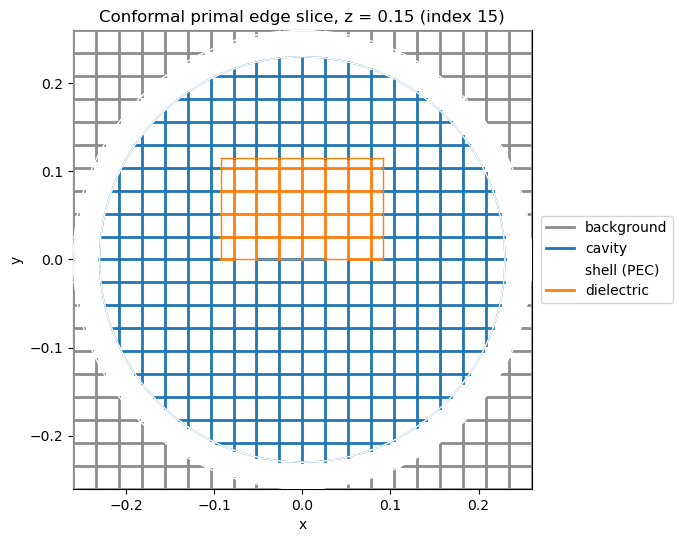

In [5]:
slice_index = Nz // 2

ax = solver.plot_conformal_primal_edge_slice(
    normal="z",
    index=slice_index,
    show_full_grid=False,
    show_stl=True,
    show_intersection_marker=False,
)

plt.show()

In [6]:
import inspect

source = inspect.getsource(grid._apply_conformal_pec_snapping)

print(
    "uses pre_snap_resolved_masks:",
    "pre_snap_resolved_masks" in source,
)

print(
    "excludes multiple crossings:",
    "multiple_crossing_positions"
    in source[source.find("candidate =") : source.find("candidate =") + 500],
)

uses pre_snap_resolved_masks: False
excludes multiple crossings: False


In [7]:
eta = grid.conformal_pec_snap_fraction
tol = 1e-12

total_violations = 0

for grid_type in (
    "primal",
    "dual",
):
    print()
    print(grid_type.upper())

    for direction in (
        "x",
        "y",
        "z",
    ):
        line_data = solver.conformal_line_data[grid_type][direction]

        conductor_interface = (
            line_data["normal_to_conductor"] | line_data["conductor_to_normal"]
        )

        fractions = line_data["effective_length_fraction"]

        violations = (
            conductor_interface & np.isfinite(fractions) & (fractions < eta - tol)
        )

        n_violations = int(np.count_nonzero(violations))

        total_violations += n_violations

        valid_fractions = fractions[conductor_interface]

        if valid_fractions.size:
            min_fraction = np.min(valid_fractions)
        else:
            min_fraction = np.nan

        print(f"{direction}: min={min_fraction:.6f}, below eta={n_violations}")

        if n_violations:
            for index_array in np.argwhere(violations):
                index = tuple(int(v) for v in index_array)

                print(
                    "   ",
                    index,
                    "f=",
                    fractions[index],
                    "alpha=",
                    line_data["alpha"][index],
                    "regions=",
                    (
                        int(line_data["start_region"][index]),
                        int(line_data["end_region"][index]),
                    ),
                )

print()
print(
    "TOTAL VIOLATIONS:",
    total_violations,
)


for grid_type in (
    "primal",
    "dual",
):
    print()
    print(grid_type.upper())

    for direction in (
        "x",
        "y",
        "z",
    ):
        face_data = solver.conformal_face_data[grid_type][direction]

        normal_pec = face_data["normal_pec"]

        fractions = face_data["effective_area_fraction"]

        values = fractions[normal_pec]

        if values.size == 0:
            print(f"{direction}: no normal-PEC faces")
            continue

        print(
            f"{direction}: "
            f"number={values.size}, "
            f"min={np.min(values):.8e}, "
            f"p1={np.percentile(values, 1):.8e}, "
            f"p5={np.percentile(values, 5):.8e}, "
            f"median={np.median(values):.8e}"
        )


limit = 0.05

for grid_type in (
    "primal",
    "dual",
):
    print()
    print(grid_type.upper())

    for direction in (
        "x",
        "y",
        "z",
    ):
        face_data = solver.conformal_face_data[grid_type][direction]

        fractions = face_data["effective_area_fraction"]

        small = face_data["normal_pec"] & np.isfinite(fractions) & (fractions < limit)

        indices = np.argwhere(small)

        print(
            direction,
            "below",
            limit,
            "=",
            len(indices),
        )

        for index_array in indices[:10]:
            index = tuple(int(v) for v in index_array)

            print(
                "   ",
                index,
                "f_A=",
                fractions[index],
            )

eta = grid.conformal_pec_snap_fraction
face_limit = 0.5 * eta**2
tol = 1e-12

total_violations = 0

for grid_type in (
    "primal",
    "dual",
):
    print()
    print(grid_type.upper())

    for direction in (
        "x",
        "y",
        "z",
    ):
        face_data = solver.conformal_face_data[grid_type][direction]

        fractions = face_data["effective_area_fraction"]

        normal_pec = face_data["normal_pec"]

        violations = (
            normal_pec & np.isfinite(fractions) & (fractions < face_limit - tol)
        )

        n_violations = int(np.count_nonzero(violations))

        total_violations += n_violations

        values = fractions[normal_pec]

        minimum = np.min(values) if values.size else np.nan

        print(
            f"{direction}: "
            f"min={minimum:.8e}, "
            f"limit={face_limit:.8e}, "
            f"below limit={n_violations}"
        )

print()
print(
    "TOTAL FACE VIOLATIONS:",
    total_violations,
)


PRIMAL
x: min=0.204444, below eta=0
y: min=0.204444, below eta=0
z: min=0.222066, below eta=0

DUAL
x: min=0.201430, below eta=0
y: min=0.209672, below eta=0
z: min=0.206194, below eta=0

TOTAL VIOLATIONS: 0

PRIMAL
x: number=582, min=3.23485808e-02, p1=5.52612018e-02, p5=1.11096239e-01, median=5.58087357e-01
y: number=675, min=3.39168082e-02, p1=5.84933116e-02, p5=1.23843798e-01, median=5.44901298e-01
z: number=846, min=5.74892663e-02, p1=5.74892663e-02, p5=1.04269160e-01, median=6.15013127e-01

DUAL
x: number=608, min=4.25074585e-02, p1=5.23550749e-02, p5=1.04835863e-01, median=6.62102056e-01
y: number=727, min=4.37830139e-02, p1=5.24861211e-02, p5=1.02123507e-01, median=5.71555264e-01
z: number=889, min=2.98873037e-02, p1=3.02352680e-02, p5=7.82605367e-02, median=4.98714889e-01

PRIMAL
x below 0.05 = 6
    (9, 1, 10) f_A= 0.0323486862466296
    (9, 1, 19) f_A= 0.032349039876772206
    (10, 2, 9) f_A= 0.04160192543996021
    (10, 2, 20) f_A= 0.04160221901789322
    (11, 1, 10) f_A= 

## Optional: anderer Querschnitt

Falls du anschließend die Geometrie aus einer zweiten Richtung prüfen willst, kannst du z. B. einen mittleren `y`-Slice verwenden.


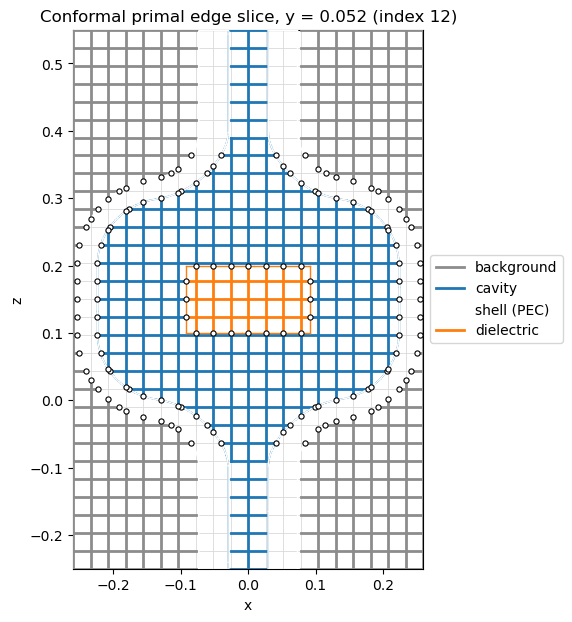

In [11]:
# Optional
ax = solver.plot_conformal_primal_edge_slice(
    normal="y",
    index=Ny // 2 + 2,
    show_full_grid=True,
    show_stl=True,
    show_intersection_marker=True,
)
plt.show()

In [22]:
pairs = (
    ("L", solver.L, grid.L),
    ("tL", solver.tL, grid.tL),
    ("iA", solver.iA, grid.iA),
    ("itA", solver.itA, grid.itA),
)

for name, solver_field, grid_field in pairs:
    print(
        f"{name}:",
        "same object =",
        solver_field is grid_field,
        "same values =",
        np.allclose(
            solver_field.toarray(),
            grid_field.toarray(),
        ),
    )

L: same object = False same values = False
tL: same object = False same values = False
iA: same object = False same values = False
itA: same object = False same values = False


In [23]:
print(
    "L_eff differs from grid.L:",
    np.max(np.abs(solver.L_eff.toarray() - grid.L.toarray())),
)

print(
    "tL_eff differs from grid.tL:",
    np.max(np.abs(solver.tL_eff.toarray() - grid.tL.toarray())),
)

print(
    "1/A_eff differs from grid.iA:",
    np.max(np.abs(1.0 / solver.A_eff.toarray() - grid.iA.toarray())),
)

print(
    "1/tA_eff differs from grid.itA:",
    np.max(np.abs(1.0 / solver.tA_eff.toarray() - grid.itA.toarray())),
)

L_eff differs from grid.L: 0.021354812383651778
tL_eff differs from grid.tL: 0.024400620162487008
1/A_eff differs from grid.iA: 54736.20133439758
1/tA_eff differs from grid.itA: 68698.47717380479
